# Repeat Petitioner Analysis

## Load libraries and data

In [1]:
# libraries
import pickle
import statistics
import matplotlib.pyplot as plt
import re
import pandas as pd
import numpy as np
from collections import Counter
from datetime import datetime
from dateutil.relativedelta import relativedelta
import random
from datetime import date, timedelta

In [2]:
with open('../data/aus/clean/aus_deidentified_min_fields.pkl', 'rb') as f:
    aus = pickle.load(f, encoding="utf-8")

with open('../data/canada/clean/can_deidentified_min_fields.pkl', 'rb') as f:
    can = pickle.load(f, encoding="utf-8")

## Distribution of authorship - frequencies and proportions

In [3]:
def author_stats(epets):
    # summary stats
    epets_df = pd.DataFrame(epets).T
    epets_df_sum = epets_df.groupby('author_id').size().reset_index(name='Count')#.sort_values(by = 'title', ascending = False)

    #print(epets_df_sum)
    
    print(f"Min val: {min(epets_df_sum['Count'])}")
    print(f"Median val: {np.median(epets_df_sum['Count'])}")
    # print(f"Median val: {statistics.median_low(epets_df_sum['Count'])}")
    print(f"Max val: {max(epets_df_sum['Count'])}")
    
    print(f"1 petition count: {len(epets_df_sum[epets_df_sum['Count'] == 1]['Count'])}")
    print(f"1 petition percentage: {round(len(epets_df_sum[epets_df_sum['Count'] == 1]['Count'])/sum(epets_df_sum['Count']),3)}")
    
    print(f">1 petition percentage: {len(epets_df_sum[epets_df_sum['Count'] > 1]['Count'])}")
    print(f">1 petition percentage: {round(1 - len(epets_df_sum[epets_df_sum['Count'] == 1]['Count'])/sum(epets_df_sum['Count']), 3)}")


#     ordered_count_list = list(epets_df_sum['Count'])
#     ordered_count_list.sort()
#     qs = np.quantile(ordered_count_list, [0.75, 0.8, 0.85, 0.9, 0.95, 0.975, 0.99])
#     print(qs)

    #len(epets_df_sum[epets_df_sum['Count'] == 1]['Count'])/sum(epets_df_sum['Count'])

In [4]:
author_stats(can)

Min val: 1
Median val: 1.0
Max val: 7
1 petition count: 1617
1 petition percentage: 0.795
>1 petition percentage: 170
>1 petition percentage: 0.205


In [5]:
author_stats(aus)

Min val: 1
Median val: 1.0
Max val: 68
1 petition count: 2664
1 petition percentage: 0.682
>1 petition percentage: 319
>1 petition percentage: 0.318


## Gender and petitioner frequency - >1 petition, >= N petitions, top 10 most prolific authors

In [6]:
def gender_pet_freq(epets, thresh1, topx):
    author_gen = pd.DataFrame(epets).T 
    author_gen = author_gen.groupby(['author_id', 'gender'])['date'].count().reset_index(name = 'count').sort_values(by = 'count', ascending = False)

    dups = author_gen[author_gen['count'] > 1].groupby('gender').count().reset_index()[['gender', 'count']]

    thresh1_df = author_gen[author_gen['count'] >= thresh1].groupby('gender').count().reset_index()[['gender', 'count']]
    
    topx_df = author_gen.iloc[0:topx].groupby('gender').count().reset_index()[['gender', 'count']]
    
    #print(thresh1_df)
    #print(topx_df)
    
    return dups, thresh1_df, topx_df

In [7]:
aus_dups, aus_thresh1, aus_topx = gender_pet_freq(aus, 10, 10)
can_dups, can_thresh1, can_topx = gender_pet_freq(can, 3, 10)

In [8]:
print(aus_dups)
print()
print(aus_thresh1)
print()
print(aus_topx)

          gender  count
0         female    116
1           male    203
2  unknown/other      1

   gender  count
0  female      3
1    male     14

   gender  count
0  female      2
1    male      8


In [9]:
print(can_dups)
print()
print(can_thresh1)
print()
print(can_topx)

          gender  count
0         female     69
1           male     99
2  unknown/other      2

   gender  count
0  female     19
1    male     31

   gender  count
0  female      6
1    male      4


## Examining signatures gained by frequent petitioners

In [10]:
## UPDATE SEEDING
def sampling_sigs(author_val_list, sig_list, N, flag, seed_in = None):
    samps = {}
    seed_list = []
    
    if seed_in == None:
        random.seed(1000)
    else:
        random.seed(seed_in)
        
    for j in range(len(author_val_list)):
        
        x = author_val_list[j]
        
        print(f"Author frequency value: {x}")
        
        samps[x] = []
        
        for i in range(1,N+1,1):
            vals = random.choices(sig_list, k=x)
            
            if flag == 'log':
                vals = [np.log(v) for v in vals]

            samps[x].append(np.average(vals))

    return samps

def signature_dups(epets, sig_field, flag):
    a = pd.DataFrame(epets).T
    a2 = a[[sig_field,'author_id']].copy()
    
    if flag == 'log':
        # SUMMING THE LOG != LOGGING THE SUM - NEED TO PONDER THIS MORE
        a2[sig_field] = [np.log(a) for a in a2[sig_field]]
    
    a2 = a2.groupby('author_id').agg(Total_Signatures=(sig_field, 'sum'),Petition_Count=(sig_field, 'count')).reset_index().sort_values(by = 'Total_Signatures', ascending = False)

    
    return a2

In [11]:
# create pipeline to run non-log and log sampling process and get all the required outputs
# these outputs can then be passed to the plotting

def full_process(epets, flag, N = 5000, seed_in = None):
    # get author name frequencies (petitioning frequencies)
    d = dict(Counter([epets[k]['author_id'] for k in epets.keys()]))
    
    # unique author-frequency values
    # author_val_list = list(set(d.values()))
    author_val_list = sorted(set(d.values()))
    
    # list of signature values
    sig_list = [epets[x]['signatures'] for x in epets.keys()]
    
    # sampling for each observed author-petitioning-frequency value
    if flag == 'norm':
        avg_out = np.average(sig_list)
    if flag == 'log':
        sig_list_log = [np.log(x) for x in sig_list] # needed to plot the average log(sig) value across the whole dataset
        avg_out = np.average(sig_list_log)
    
    samps = sampling_sigs(author_val_list, sig_list, N, flag, seed_in)
    a1_out = signature_dups(epets, 'signatures', flag)
        
    quant_d = {'lower': [], 'upper': []}
    for x in samps.keys():
        quant_d['lower'].append(np.quantile(samps[x], 0.025))
        quant_d['upper'].append(np.quantile(samps[x], 0.975))
    
    # print(a1_out.sort_values(by = 'Petition_Count'))
    
    return avg_out, samps, a1_out, quant_d


## Figure 5

In [12]:
avg_sig_vals = []
observed_avg_dfs = []
samps_list = []
quant_ds = []

pets = [aus, can]
tags = ['log', 'log']
seeds = [300, 400]
N = 5000

for i in range(len(pets)):
    avg, samps, df_out, quant_d = full_process(pets[i], tags[i], N, seeds[i])
    avg_sig_vals.append(avg)
    observed_avg_dfs.append(df_out)
    samps_list.append(samps)
    quant_ds.append(quant_d)

Author frequency value: 1
Author frequency value: 2
Author frequency value: 3
Author frequency value: 4
Author frequency value: 5
Author frequency value: 6
Author frequency value: 7
Author frequency value: 8
Author frequency value: 9
Author frequency value: 10
Author frequency value: 11
Author frequency value: 14
Author frequency value: 16
Author frequency value: 21
Author frequency value: 24
Author frequency value: 29
Author frequency value: 34
Author frequency value: 39
Author frequency value: 41
Author frequency value: 45
Author frequency value: 68
Author frequency value: 1
Author frequency value: 2
Author frequency value: 3
Author frequency value: 4
Author frequency value: 5
Author frequency value: 6
Author frequency value: 7


0
1


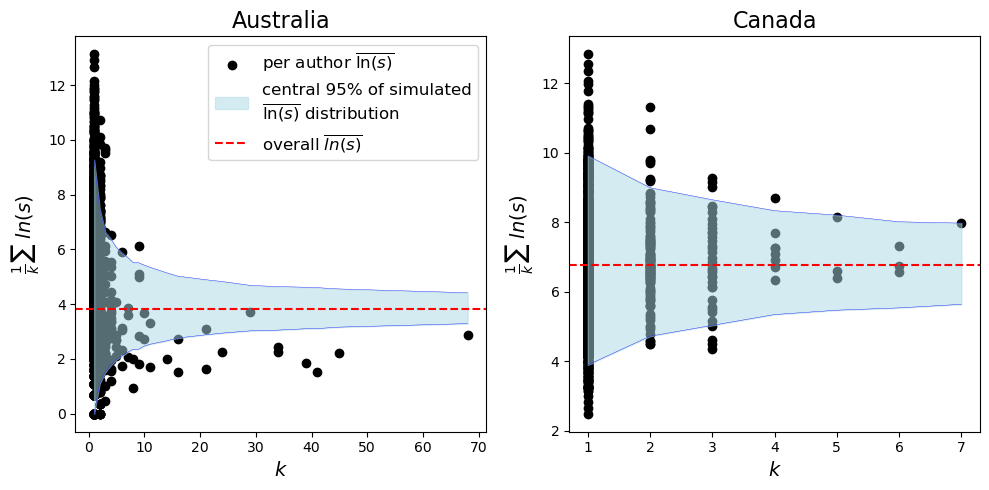

In [25]:
axes = [0, 1]
titles = ['Australia', 'Canada']

fig, axs = plt.subplots(nrows=1, ncols=2, figsize=(10, 5))

for i in range(2):
    
    print(i)

    # axs[axes[i]].set_yscale('log') # log scale only for the non-logged outcomes
    
    obs = observed_avg_dfs[i]
    obs['Avg_Sig'] = obs['Total_Signatures']/obs['Petition_Count']
    axs[axes[i]].scatter(obs['Petition_Count'], obs['Avg_Sig'], color = 'black', label = r'per author $\overline{\ln(s)}$') #'Observed Values' # Observed 
    
    samps = samps_list[i]
    quant_d = quant_ds[i]
    axs[axes[i]].plot(samps.keys(), quant_d['lower'], color='blue', lw =0.25)
    axs[axes[i]].plot(samps.keys(), quant_d['upper'], color='blue', lw =0.25)
    axs[axes[i]].fill_between(samps.keys(), quant_d['lower'], quant_d['upper'], color='lightblue', alpha=0.5, label = 'central 95% of simulated\n$\overline{\ln(s)}$ distribution')

    axs[axes[i]].axhline(y=avg_sig_vals[i], color='r', linestyle='--', lw = 1.5, label=r'overall $\overline{ln(s)}$') #Observed Overall\nAverage Signature Value

    axs[axes[i]].set_title(titles[i], fontsize = 16)
    
    axs[axes[i]].set_ylabel(r'$\frac{1}{k}\sum~ln(s)$', fontsize = 14) # _{S_{0}}^{S_{n}}
    axs[axes[i]].set_xlabel(r'$k$', fontsize = 14)
    
    if i == 0:
        axs[axes[i]].legend(fontsize=12)

plt.tight_layout()

# plt.savefig('../figures/repeat_authors_log_sig_only_final2.png', dpi = 300, bbox_inches='tight')

plt.show()